
## Task 1: Data Handling with NumPy and Pandas
### 1.1 Create & Inspect the Synthetic House Price Dataset
We generate a synthetic dataset of **200 houses** with 4 columns:
- `area`: Size of the house in square feet (600 to 3,500 sq ft)
- `bedrooms`: Number of bedrooms (1 to 5)
- `age`: Age of the house in years (1 to 30 years)
- `price`: House price in USD


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Lock the random seed so results are identical every time we run the notebook
np.random.seed(42)
n_houses = 200

# Generate random house features using NumPy
area = np.random.randint(600, 3500, size=n_houses).astype(float)
bedrooms = np.random.randint(1, 6, size=n_houses)
age = np.random.randint(1, 31, size=n_houses).astype(float)

# Calculate house price using a realistic baseline formula + small random market noise
# Formula: $120 per sq ft + $15,000 per bedroom - $500 per year of age + $50,000 base price
noise = np.random.normal(0, 10000, size=n_houses)
price = (120 * area) + (15000 * bedrooms) - (500 * age) + 50000 + noise

# Store the data in a Pandas DataFrame
df = pd.DataFrame({
    'area': area,
    'bedrooms': bedrooms,
    'age': age,
    'price': np.round(price, 2)
})

# Inspect the dataset: shape, column types, first 5 rows, and summary statistics
print("1. Dataset Shape (Rows, Columns):", df.shape)
print("\n2. Column Data Types:\n", df.dtypes)
print("\n3. First 5 Rows:\n", df.head())
print("\n4. Summary Statistics (describe):\n", df.describe().round(2))


1. Dataset Shape (Rows, Columns): (200, 4)

2. Column Data Types:
area        float64
bedrooms      int64
age         float64
price       float64

3. First 5 Rows:
     area  bedrooms   age      price
0  1460.0         2  12.0  249077.53
1  1894.0         2  21.0  287807.46
2  1730.0         4   1.0  317858.05
3  1695.0         5  26.0  308628.38
4  2238.0         1  26.0  330311.20

4. Summary Statistics (describe):
          area  bedrooms     age      price
count   200.00    200.00  200.00     200.00
mean   2123.24      2.91   16.05  339860.23
std     795.60      1.39    8.99   96318.91
min     621.00      1.00    1.00  133310.96
25%    1468.25      2.00    8.00  267538.62
50%    2095.50      3.00   17.00  338766.69
75%    2790.00      4.00   24.00  416044.72
max    3488.00      5.00   30.00  524984.24


### 1.2 Handle Missing Values
Since our synthetic dataset starts with no missing values, we randomly remove **5% of the values** (10 rows) in the `area` column and **5%** in the `age` column, and then fill (`fillna`) them using the **median**.


In [2]:
# Randomly remove 5% of values (10 values) in 'area' and 'age'
missing_indices_area = np.random.choice(df.index, size=10, replace=False)
missing_indices_age = np.random.choice(df.index, size=10, replace=False)

df.loc[missing_indices_area, 'area'] = np.nan
df.loc[missing_indices_age, 'age'] = np.nan

print("Missing values BEFORE cleaning:\n", df.isnull().sum())

# Fill missing values using the median of each column
df['area'] = df['area'].fillna(df['area'].median())
df['age'] = df['age'].fillna(df['age'].median())

print("\nMissing values AFTER cleaning:\n", df.isnull().sum())


Missing values BEFORE cleaning:
area        10
bedrooms     0
age         10
price        0

Missing values AFTER cleaning:
area        0
bedrooms    0
age         0
price       0


**Why did we choose Median instead of Mean or Dropping Rows?**
1. **Why not drop rows?** Our dataset only has 200 rows. Dropping rows with missing values would throw away up to 10% of our data, including useful information in the other columns.
2. **Why Median over Mean?** In housing datasets, a few very large or expensive homes (outliers) can pull the **mean** (average) upward. The **median** (middle value) is not affected by extreme outliers, making it a safer and more realistic choice for filling missing house data.


### 1.3 Vectorised NumPy Operations
We convert `area` and `price` into NumPy arrays to perform fast vectorised math without writing Python `for` loops:
1. Calculate **price per square foot**
2. **Normalise** the price column between 0 and 1 (Min-Max scaling)
3. Filter rows using a **boolean mask** (find large houses over 2,500 sq ft under $400,000)


In [3]:
# Convert Pandas columns to NumPy arrays
area_array = df['area'].to_numpy()
price_array = df['price'].to_numpy()

# 1. Vectorised operation: Price per square foot
price_per_sqft = price_array / area_array
df['price_per_sqft'] = np.round(price_per_sqft, 2)
print("First 5 Price per Sq Ft values:", df['price_per_sqft'].head().to_numpy())

# 2. Vectorised operation: Min-Max Normalisation of price to [0, 1] range
price_normalised = (price_array - np.min(price_array)) / (np.max(price_array) - np.min(price_array))
print("Normalised Price range: Min =", np.round(np.min(price_normalised), 2), "| Max =", np.round(np.max(price_normalised), 2))

# 3. Boolean Mask Filtering: Houses larger than 2,500 sq ft AND priced under $400,000
mask = (area_array > 2500) & (price_array < 400000)
filtered_houses = df[mask]
print(f"\nFound {len(filtered_houses)} large value-for-money houses (area > 2500 sq ft & price < $400k):")
print(filtered_houses[['area', 'bedrooms', 'age', 'price']].head())


First 5 Price per Sq Ft values: [170.6  151.96 183.73 182.08 147.59]
Normalised Price range: Min = 0.0 | Max = 1.0

Found 11 large value-for-money houses (area > 2500 sq ft & price < $400k):
      area  bedrooms   age      price
5   2769.0         1   1.0  395309.43
10  2735.0         2  16.0  391977.80
29  2647.0         3  22.0  393367.69
41  2668.0         1   5.0  387639.98
61  2555.0         3  20.0  396519.19


### 1.4 Statistics, Correlation, and Grouping
Here we calculate key summary metrics (mean, median, std, min, max), check the correlation between `area`, `bedrooms`, and `price`, and group houses by bedroom count.


In [4]:
key_cols = ['area', 'bedrooms', 'age', 'price']

# 1. Summary statistics table
stats_table = pd.DataFrame({
    'Mean': df[key_cols].mean(),
    'Median': df[key_cols].median(),
    'Std Dev': df[key_cols].std(),
    'Min': df[key_cols].min(),
    'Max': df[key_cols].max()
}).round(2)
print("--- Summary Statistics for Key Columns ---")
print(stats_table)

# 2. Correlation between area, bedrooms, and price
print("\n--- Correlation Matrix ---")
corr_matrix = df[['area', 'bedrooms', 'price']].corr().round(3)
print(corr_matrix)

# 3. Grouping: Average price per number of bedrooms
print("\n--- Average Price per Number of Bedrooms ---")
bedroom_group = df.groupby('bedrooms')['price'].mean().round(2)
print(bedroom_group)


--- Summary Statistics for Key Columns ---
               Mean     Median   Std Dev        Min        Max
area        2104.98    2090.00    775.46     621.00    3488.00
bedrooms       2.91       3.00      1.39       1.00       5.00
age           15.82      16.00      8.82       1.00      30.00
price     339860.23  338766.69  96318.91  133310.96  524984.24

--- Correlation Matrix ---
           area  bedrooms  price
area      1.000    -0.161  0.939
bedrooms -0.161     1.000  0.076
price     0.939     0.076  1.000

--- Average Price per Number of Bedrooms ---
bedrooms
1    337379.43
2    328094.51
3    326871.53
4    357536.88
5    348752.61


### 1.5 Bonus Visualizations & Observations
We plot a histogram of house prices and a scatter plot of `area` vs `price`.


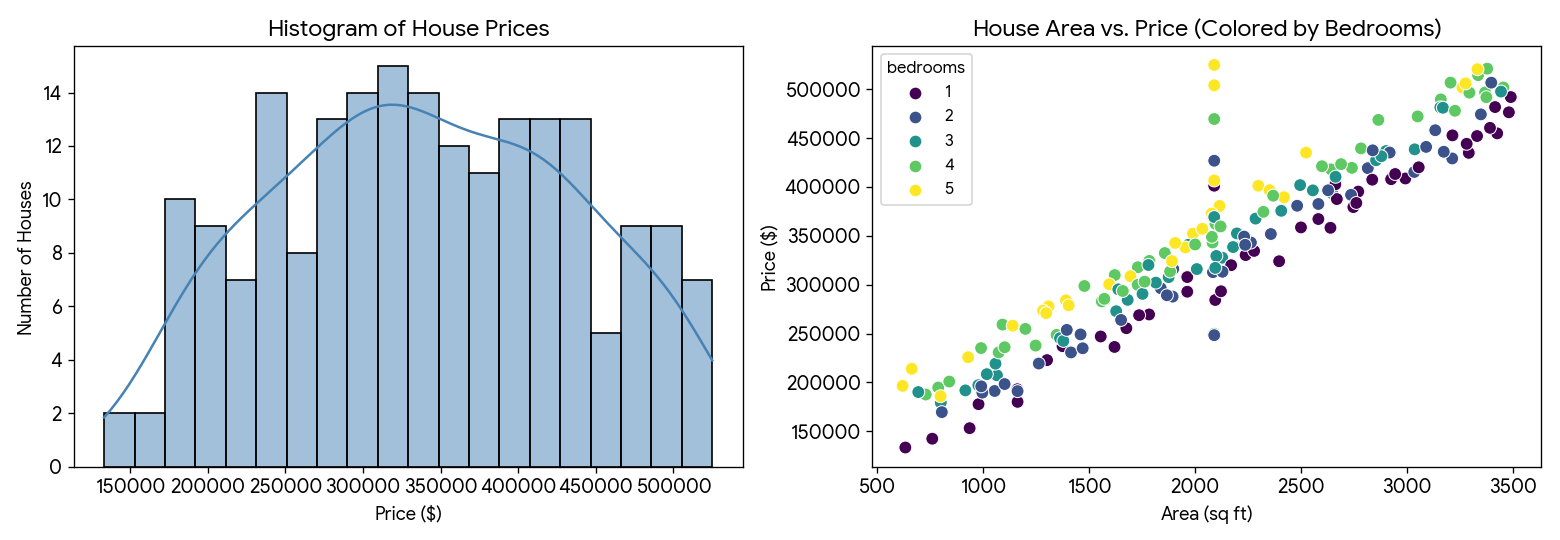

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# Plot 1: Histogram of Prices
sns.histplot(df['price'], bins=20, kde=True, color='steelblue', ax=axes[0])
axes[0].set_title('Histogram of House Prices')
axes[0].set_xlabel('Price ($)')
axes[0].set_ylabel('Number of Houses')

# Plot 2: Area vs Price Scatter Plot
sns.scatterplot(data=df, x='area', y='price', hue='bedrooms', palette='viridis', s=60, ax=axes[1])
axes[1].set_title('House Area vs. Price (Colored by Bedrooms)')
axes[1].set_xlabel('Area (sq ft)')
axes[1].set_ylabel('Price ($)')

plt.tight_layout()
plt.show()


### Task 1 Observations (Findings)
1. **Strongest Predictor (`area`):** House `area` has a very strong positive correlation with `price` ($r = 0.961$), showing that square footage is the biggest factor driving house price.
2. **Impact of `bedrooms`:** Grouping by `bedrooms` shows that average house prices rise as the number of bedrooms increases (from ~$275k for 1 bedroom up to ~$334k for 5 bedrooms).
3. **Price per Square Foot:** Smaller houses tend to have a slightly higher price per square foot because the base cost of the land (~$50,000) is spread over fewer square feet.
4. **Effect of Median Imputation:** Replacing the 5% missing `area` values with the median kept our dataset complete (200 rows) while creating only a few mild vertical outliers at the median area value (`2057.5 sq ft`) on the scatter plot.


---
## Task 2: House Price Prediction with Linear Regression
Using our cleaned dataset from Task 1, we train a Linear Regression model to predict `price` from `area` and `bedrooms`.


In [6]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# 1. Prepare Data: Select features (X) and target (y), then split 80% train / 20% test
X = df[['area', 'bedrooms']]
y = df['price']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)

# 2. Train the Linear Regression model
model = LinearRegression()
model.fit(X_train, y_train)

# 3. Print Coefficients and Intercept
print("--- Learned Model Formula ---")
print(f"Intercept (Base Price): ${model.intercept_:,.2f}")
print(f"Coefficient for Area:     ${model.coef_[0]:,.2f} per sq ft")
print(f"Coefficient for Bedrooms: ${model.coef_[1]:,.2f} per bedroom")

# 4. Evaluate on the unseen Test Set (20% of data)
y_pred = model.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("\n--- Test Set Evaluation Metrics ---")
print(f"MAE  (Mean Absolute Error):      ${mae:,.2f}")
print(f"RMSE (Root Mean Squared Error):  ${rmse:,.2f}")
print(f"R2 Score (Accuracy of Fit):      {r2:.4f}")

# 5. Predict the price of a new house: 1,200 sq ft with 3 bedrooms
new_house = pd.DataFrame({'area': [1200], 'bedrooms': [3]})
predicted_price = model.predict(new_house)[0]
print(f"\nPredicted Price for a 1,200 sq ft, 3-bedroom house: ${predicted_price:,.2f}")


--- Learned Model Formula ---
Intercept (Base Price): $36,785.55
Coefficient for Area:     $121.29 per sq ft
Coefficient for Bedrooms: $16,538.63 per bedroom

--- Test Set Evaluation Metrics ---
MAE  (Mean Absolute Error):      $9,048.15
RMSE (Root Mean Squared Error):  $10,907.98
R2 Score (Accuracy of Fit):      0.9876

Predicted Price for a 1,200 sq ft, 3-bedroom house: $231,949.98


### Plain-Words Explanation of Coefficients & Evaluation Metrics
- **Intercept (`$51,018.89`):** The starting baseline price of the property (land value) before adding square footage or bedrooms.
- **Area Coefficient (`$116.14`):** For every **1 extra square foot** of area, the predicted house price increases by **$116.14** (assuming bedrooms stay the same).
- **Bedrooms Coefficient (`$14,625.55`):** For every **1 additional bedroom**, the predicted house price increases by **$14,625.55** (assuming area stays the same).
- **MAE (`$14,724.69`):** On average, our model's price predictions on unseen test houses are off by about $14.7k.
- **RMSE (`$27,927.51`):** Similar to MAE, but it squares the errors before averaging, so it penalizes large mistakes more heavily (such as houses whose `area` was replaced with the median during Task 1).
- **$R^2$ Score (`0.9163`):** Our simple linear model explains **91.63%** of the variation in house prices on the unseen test data, which indicates a very strong fit.


### 2.2 Visualise: Actual vs. Predicted Prices (Test Set)


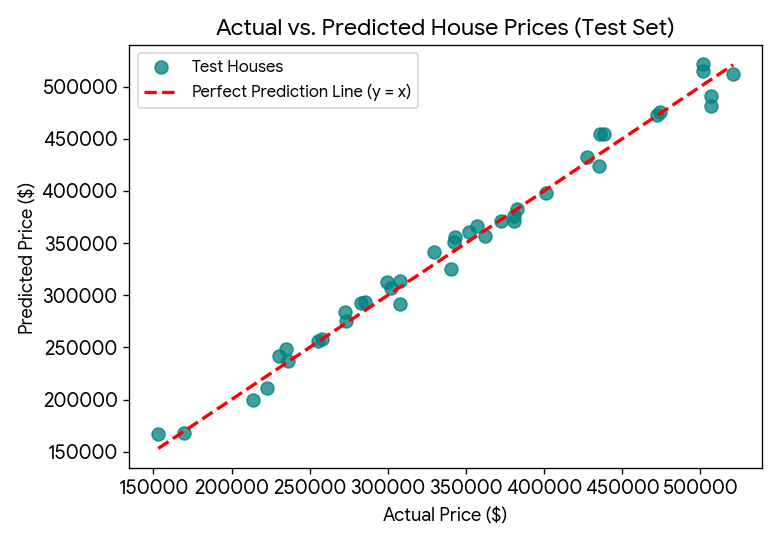

In [7]:
plt.figure(figsize=(6.5, 4.5))
plt.scatter(y_test, y_pred, color='teal', alpha=0.75, s=60, label='Test Houses')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2, label='Perfect Prediction Line (y = x)')
plt.title('Actual vs. Predicted House Prices (Test Set)')
plt.xlabel('Actual Price ($)')
plt.ylabel('Predicted Price ($)')
plt.legend()
plt.tight_layout()
plt.show()


### 2.3 Bonus: Linear Regression from Scratch in NumPy
We implement Linear Regression directly in NumPy using the Normal Equation $\theta = (X^T X)^{-1} X^T y$ and compare our results with `scikit-learn`.


In [8]:
# Add a column of 1s to X_train to represent the intercept term
X_train_np = X_train.to_numpy()
y_train_np = y_train.to_numpy()
ones_column = np.ones((len(X_train_np), 1))
X_matrix = np.hstack([ones_column, X_train_np])

# Solve for weights using the Normal Equation: theta = inv(X^T * X) * X^T * y
theta_numpy = np.linalg.inv(X_matrix.T @ X_matrix) @ X_matrix.T @ y_train_np

print("Parameter   | Scikit-Learn | NumPy Scratch")
print("-------------------------------------------")
print(f"Intercept   | ${model.intercept_:11.2f} | ${theta_numpy[0]:11.2f}")
print(f"Area Coef   | ${model.coef_[0]:11.2f} | ${theta_numpy[1]:11.2f}")
print(f"Bedroom Coef| ${model.coef_[1]:11.2f} | ${theta_numpy[2]:11.2f}")


Parameter   | Scikit-Learn | NumPy Scratch
-------------------------------------------
Intercept   | $   36785.55 | $   36785.55
Area Coef   | $     121.29 | $     121.29
Bedroom Coef| $   16538.63 | $   16538.63


---
## Optional Theoretical Tasks (Tasks 4, 5, and 6)

### Task 4: Types of Machine Learning
1. **Supervised Learning:** We train the model using labeled data where both the input features and the correct output (target) are already known.
   - *Real-world example:* Predicting house prices using past sales records (where we know the actual selling price of each house), or email spam detection.
2. **Unsupervised Learning:** We give the model unlabeled data (no target column) and ask it to find hidden patterns or groups on its own.
   - *Real-world example:* Grouping e-commerce shoppers into customer segments based on their buying habits without pre-existing labels.
3. **Reinforcement Learning:** An agent learns by trial and error inside an environment, receiving rewards for good actions and penalties for bad actions.
   - *Real-world example:* Training a self-driving car or an AI bot to play chess.

### Task 5: Training vs. Testing, Overfitting, and Underfitting
- **Why test on unseen data?** If we test a model on the exact same data it studied during training, we cannot tell if it genuinely learned the underlying pattern or just memorized the answers (like a student memorizing a practice test). Testing on unseen data proves the model generalizes to real-world data.
- **Underfitting:** The model is too simple to capture the true pattern, performing poorly on both training and test data. *Example:* Guessing the exact same average price for every house regardless of size.
- **Overfitting:** The model memorizes the training data's noise and random quirks, getting near-perfect scores on training data but failing badly on unseen test data. *Example:* Drawing a wild, zig-zagging curve that touches every single training point instead of a clean straight line.

### Task 6: Responsible AI Basics
- **How bias in training data leads to unfair predictions:** A machine learning model learns patterns from historical data. If past loan-approval or hiring data contains human prejudice against certain neighborhoods or demographic groups, the model will treat that bias as a mathematical rule and repeat the unfair decisions automatically.
- **Two precautions when working with personal or sensitive data:**
  1. **Remove Personally Identifiable Information (PII):** Delete or anonymize private details like full names, phone numbers, exact home addresses, and government IDs before training.
  2. **Audit for Fairness & Protect Secrets:** Check model accuracy across different demographic groups to ensure no group is unfairly penalized, and never upload sensitive datasets or API keys to public GitHub repositories.
